<a href="https://colab.research.google.com/github/eoinleen/AKTA-Prime_final/blob/main/Plotting_K11_specificity_gates.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# K11 / K33 binder specificity triage

**Run All, then upload your merged triage xlsx** (triage_full_merged.xlsx). In Colab a file
picker pops up; the five plots render below it.

Convention: **Delta = K33 - K11**, so **positive Delta dG = K11-preferring**.

Pick plots via `PLOTS` in the config cell. Available: strain, diagonal, distort_sasa, mechanism, affinity, alignment.
Gate, fonts, marker size, and error-bar/greying toggles are all editable there too.

In [ ]:
# ============ CONFIG (edit here) ============
%matplotlib inline
import io, sys, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# --- how to show uncertainty ---
SHOW_ERRORBARS = True    # draw +/- sd bars (sd propagated for the deltas); let the reader judge
GATE           = False   # True: grey out points failing the gate below; False: show all equally

# --- reliability gate (only used when GATE=True, and for the summary table) ---
SD_MAX = 3.0      # max dG_separated sd (REU) on EACH linkage arm, over the 10 relaxes
CE_MAX = 1.2      # max ce_rmsd_C (binder self-RMSD, A); <1.2 = same fold. None to skip
XLSX   = None     # optional: a path string to load instead of the upload button

# --- which plots to draw, in order ---
# available: "strain", "diagonal", "distort_sasa", "mechanism", "affinity", "alignment"
PLOTS = ["strain", "diagonal", "distort_sasa"]
DSASA_COLOR = "delta_hphobic"   # colour for distort_sasa: "delta_hphobic" or "abs_hphobic"

# --- fold-flag thresholds (alignment-plot colour); kept in step with CE_MAX ---
FLAG_CE   = 1.2   # ce_rmsd_C above this => "fold_unreliable" (binder fold really differs)
FLAG_RMSD = 5.0   # both rmsd_A and rmsd_B above this => "divergent" (Ubs both repositioned)

# --- fonts / style ---
plt.rcParams.update({
    "font.family":     "DejaVu Sans",   # e.g. "Arial", "Helvetica"
    "axes.titlesize":   1,
    "axes.labelsize":   10,
    "xtick.labelsize":   9,
    "ytick.labelsize":   9,
    "legend.fontsize":   9,
    "figure.dpi":      600,
})
ANNOT_SIZE  = 8      # EL point-label size
MARKER_SIZE = 95     # scatter marker size
SAVE_DPI    = 600    # png export resolution

# --- non-overlapping labels (adjustText; auto-installs in Colab) ---
try:
    from adjustText import adjust_text
except ImportError:
    try:
        import subprocess
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "adjustText"], check=True)
        from adjustText import adjust_text
    except Exception:
        adjust_text = None
        print("adjustText unavailable - labels fall back to fixed offsets")

def label_points(ax, xs, ys, labels):
    txt = [ax.text(float(x), float(y), str(t), fontsize=ANNOT_SIZE)
           for x, y, t in zip(xs, ys, labels) if pd.notna(x) and pd.notna(y)]
    if adjust_text is not None and txt:
        try:
            adjust_text(txt, ax=ax, arrowprops=dict(arrowstyle="-", color="0.6", lw=0.5))
        except Exception as e:
            print("adjust_text skipped:", e)
    return txt

In [ ]:
# ============ data prep ============
def build_df(src):
    def _read(h):
        s = io.BytesIO(src) if isinstance(src, (bytes, bytearray)) else src
        return pd.read_excel(s, header=h)
    df = _read(0)
    if "dG_separated_k11" not in [str(c).strip() for c in df.columns]:
        df = _read(1)                                   # skip a banner row
    df.columns = [str(c).strip() for c in df.columns]
    for c in ["rmsd_A", "rmsd_B", "ce_rmsd_C"]:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    def parse_kd(x):
        if pd.isna(x): return (np.nan, False)
        s = str(x).strip()
        if s.lower() in ("", "n.d.", "nd"): return (np.nan, False)
        cens = s[:1] in "<>"
        try:    return (float(s.lstrip("<>").strip()), cens)
        except ValueError: return (np.nan, False)
    df["Kd"], df["Kd_censored"] = zip(*df["Kd_nM"].map(parse_kd))

    df["dDG"]    = df.dG_separated_k33       - df.dG_separated_k11   # + => K11-pref
    df["dSASA"]  = df.dSASA_int_k33          - df.dSASA_int_k11      # - => K11 buries more
    df["dunsat"] = df.delta_unsatHbonds_k33  - df.delta_unsatHbonds_k11

    # propagated sd for the delta axes (independent arms): sqrt(a^2 + b^2)
    df["ddG_err"] = np.sqrt(df.dG_separated_k11_sd**2 + df.dG_separated_k33_sd**2)
    if {"dSASA_int_k11_sd", "dSASA_int_k33_sd"}.issubset(df.columns):
        df["dSASA_err"] = np.sqrt(df.dSASA_int_k11_sd**2 + df.dSASA_int_k33_sd**2)
    else:
        df["dSASA_err"] = np.nan

    ce_ok = True if CE_MAX is None else (df.ce_rmsd_C < CE_MAX)
    df["reliable"] = (df.dG_separated_k11_sd < SD_MAX) & (df.dG_separated_k33_sd < SD_MAX) & ce_ok

    df["rmsd_max"] = df[["rmsd_A", "rmsd_B"]].max(axis=1)
    df["flag"] = np.where(df.ce_rmsd_C > FLAG_CE, "fold_unreliable",
                 np.where(df[["rmsd_A", "rmsd_B"]].min(axis=1) > FLAG_RMSD, "divergent", "conserved"))
    if {"distort_k11", "distort_k33"}.issubset(df.columns):
        df["ddistort"] = df["distort_k33"] - df["distort_k11"]
    if {"dSASA_hphobic_k11", "dSASA_hphobic_k33"}.issubset(df.columns):
        df["dhphobic"]   = df.dSASA_hphobic_k33 - df.dSASA_hphobic_k11        # K33 - K11
        df["abs_hphobic"] = (df.dSASA_hphobic_k11 + df.dSASA_hphobic_k33) / 2  # mean per binder
    return df

In [ ]:
# ============ plots ============
def _ebar(ax, x, y, xerr=None, yerr=None):
    if SHOW_ERRORBARS:
        ax.errorbar(x, y, xerr=xerr, yerr=yerr, fmt="none",
                    ecolor="0.7", elinewidth=0.8, capsize=2, zorder=1)

def plot_mechanism(df):
    fig, ax = plt.subplots(figsize=(8,6.3))
    _ebar(ax, df.dSASA, df.dDG, xerr=df.dSASA_err, yerr=df.ddG_err)
    if GATE:
        rel, unrel = df[df.reliable], df[~df.reliable]
        sc = ax.scatter(rel.dSASA, rel.dDG, c=rel.dunsat, cmap="coolwarm", vmin=-8, vmax=8,
                        s=MARKER_SIZE, edgecolor="k", zorder=3)
        ax.scatter(unrel.dSASA, unrel.dDG, facecolor="none", edgecolor="0.65",
                   s=MARKER_SIZE, zorder=2, label="gated out (unreliable)")
        ax.legend(loc="lower left")
    else:
        sc = ax.scatter(df.dSASA, df.dDG, c=df.dunsat, cmap="coolwarm", vmin=-8, vmax=8,
                        s=MARKER_SIZE, edgecolor="k", zorder=3)
    label_points(ax, df.dSASA, df.dDG, df.EL)
    ax.axhline(0, color="0.85", lw=1); ax.axvline(0, color="0.85", lw=1)
    ax.set_xlabel("Delta dSASA_int (K33-K11, A^2)   left = K11 buries more")
    ax.set_ylabel("Delta dG_separated (K33-K11, REU)   up = K11-preferring")
    cb = fig.colorbar(sc); cb.set_label("Delta unsat-Hbonds (K33-K11)   + = K33 leaves more buried polars")
    ax.set_title("K11 specificity: magnitude vs mechanism")
    fig.tight_layout(); fig.savefig("fig1_specificity_mechanism.png", dpi=SAVE_DPI); plt.show()

def plot_diagonal(df):
    fig, ax = plt.subplots(figsize=(6.8,6.8))
    _ebar(ax, df.dG_separated_k11, df.dG_separated_k33,
          xerr=df.dG_separated_k11_sd, yerr=df.dG_separated_k33_sd)
    if GATE:
        rel, unrel = df[df.reliable], df[~df.reliable]
        ax.scatter(rel.dG_separated_k11, rel.dG_separated_k33, c="C0", s=MARKER_SIZE, edgecolor="k", zorder=3)
        ax.scatter(unrel.dG_separated_k11, unrel.dG_separated_k33, c="0.7", s=MARKER_SIZE, zorder=3)
    else:
        ax.scatter(df.dG_separated_k11, df.dG_separated_k33, c="C0", s=MARKER_SIZE, edgecolor="k", zorder=3)
    label_points(ax, df.dG_separated_k11, df.dG_separated_k33, df.EL)
    lo = min(df.dG_separated_k11.min(), df.dG_separated_k33.min()) - 5
    hi = max(df.dG_separated_k11.max(), df.dG_separated_k33.max()) + 5
    ax.plot([lo,hi], [lo,hi], "k--", lw=1, label="K11 = K33")
    ax.set_xlim(lo,hi); ax.set_ylim(lo,hi)
    ax.set_xlabel("dG_separated K11 (REU)"); ax.set_ylabel("dG_separated K33 (REU)")
    ax.set_title("Above diagonal = K11-preferring (K33 weaker)")
    ax.legend(); fig.tight_layout(); fig.savefig("fig2_k11_vs_k33.png", dpi=SAVE_DPI); plt.show()

def plot_validation(df):
    v = (df if not GATE else df[df.reliable]).copy()
    v = v[v.Kd.notna()]
    v["logKd"] = np.log10(v.Kd)
    fig, ax = plt.subplots(figsize=(6.8,5.2))
    _ebar(ax, v.dG_separated_k11, v.logKd, xerr=v.dG_separated_k11_sd)
    for cens, mk in [(False, "o"), (True, "v")]:
        s = v[v.Kd_censored == cens]
        ax.scatter(s.dG_separated_k11, s.logKd, marker=mk, s=MARKER_SIZE, c="C3", edgecolor="k", zorder=3)
    label_points(ax, v.dG_separated_k11, v.logKd, v.EL)
    ax.set_xlabel("dG_separated K11 (REU)"); ax.set_ylabel("log10 Kd (nM, K11)")
    ax.set_title("dG vs affinity  (v = upper-bound Kd)")
    try:
        from scipy.stats import spearmanr
        vv = v[~v.Kd_censored]
        if len(vv) > 2:
            rho, p = spearmanr(vv.dG_separated_k11, vv.logKd)
            ax.text(0.04, 0.96, f"Spearman rho={rho:.2f}, p={p:.2f}  (n={len(vv)})",
                    transform=ax.transAxes, va="top", fontsize=ANNOT_SIZE+1)
    except ImportError:
        pass
    fig.tight_layout(); fig.savefig("fig3_dG_vs_Kd.png", dpi=SAVE_DPI); plt.show()

def plot_alignment(df):
    from matplotlib.lines import Line2D
    colors = {"conserved":"C2", "divergent":"C1", "fold_unreliable":"0.6"}
    fig, ax = plt.subplots(figsize=(7.5,6))
    _ebar(ax, df.rmsd_max, df.dDG, yerr=df.ddG_err)
    for _, r in df.iterrows():
        ax.scatter(r.rmsd_max, r.dDG, c=colors.get(r.flag, "0.6"), s=MARKER_SIZE+10,
                   edgecolor="k", linewidth=0.8, zorder=3)
    label_points(ax, df.rmsd_max, df.dDG, df.EL)
    ax.axhline(0, color="0.85", lw=1)
    ax.set_xscale("symlog", linthresh=2)
    ax.set_xlabel("max(rmsd_A, rmsd_B)  (Ub displacement K11 vs K33, A)   right = pose repositioned")
    ax.set_ylabel("Delta dG (K33-K11, REU)   up = K11-preferring")
    ax.set_title("Structural divergence vs energetic preference")
    leg = [Line2D([0],[0], marker="o", color="w", markerfacecolor=c, markersize=9, label=k)
           for k, c in colors.items()]
    ax.legend(handles=leg, loc="best", title="cealign fold flag")
    fig.tight_layout(); fig.savefig("fig4_alignment_vs_energy.png", dpi=SAVE_DPI); plt.show()

def plot_strain(df):
    if "ddistort" not in df.columns:
        print("(no distort_k11/k33 columns merged in - skipping strain plot)"); return
    sub = df[df.ddistort.notna()]
    fig, ax = plt.subplots(figsize=(7.5,6))
    _ebar(ax, sub.ddistort, sub.dDG, yerr=sub.ddG_err)
    if GATE:
        rel, unrel = sub[sub.reliable], sub[~sub.reliable]
        ax.scatter(rel.ddistort, rel.dDG, c="C0", s=MARKER_SIZE, edgecolor="k", zorder=3)
        ax.scatter(unrel.ddistort, unrel.dDG, c="0.7", s=MARKER_SIZE, zorder=3)
    else:
        ax.scatter(sub.ddistort, sub.dDG, c="C0", s=MARKER_SIZE, edgecolor="k", zorder=3)
    label_points(ax, sub.ddistort, sub.dDG, sub.EL)
    ax.axhline(0, color="0.85", lw=1); ax.axvline(0, color="0.85", lw=1)
    ax.set_xlabel("Delta distort (K33-K11, A)   right = K33 di-Ub strained from design")
    ax.set_ylabel("Delta dG_separated (K33-K11, REU)   up = K11-preferring")
    ax.set_title("Strain vs energy: do they agree on K11-specificity?")
    fig.tight_layout(); fig.savefig("fig5_strain_vs_energy.png", dpi=SAVE_DPI); plt.show()

def plot_distort_sasa(df):
    if "ddistort" not in df.columns:
        print("(no distort columns merged in - skipping distort-vs-dSASA)"); return
    sub = df[df.ddistort.notna()]
    if DSASA_COLOR == "abs_hphobic" and "abs_hphobic" in df.columns:
        cvar, clabel, cmap = "abs_hphobic", "mean hydrophobic dSASA (A^2)", "viridis"
    else:
        cvar, clabel, cmap = "dhphobic", "Delta hydrophobic dSASA (K33-K11, A^2)", "coolwarm"
    fig, ax = plt.subplots(figsize=(8,6.3))
    _ebar(ax, sub.ddistort, sub.dSASA, yerr=sub.dSASA_err)
    sc = ax.scatter(sub.ddistort, sub.dSASA, c=sub[cvar], cmap=cmap,
                    s=MARKER_SIZE, edgecolor="k", zorder=3)
    label_points(ax, sub.ddistort, sub.dSASA, sub.EL)
    ax.axhline(0, color="0.85", lw=1); ax.axvline(0, color="0.85", lw=1)
    ax.set_xlabel("Delta distort (K33-K11, A)   right = K33 di-Ub strained from design")
    ax.set_ylabel("Delta dSASA_int (K33-K11, A^2)   up = K33 buries more")
    cb = fig.colorbar(sc); cb.set_label(clabel)
    ax.set_title("Strain vs interface size")
    fig.tight_layout(); fig.savefig("fig6_distort_vs_dSASA.png", dpi=SAVE_DPI); plt.show()

PLOT_FUNCS = {"mechanism": plot_mechanism, "diagonal": plot_diagonal, "affinity": plot_validation,
              "alignment": plot_alignment, "strain": plot_strain, "distort_sasa": plot_distort_sasa}

def run_all(df):
    print(f"{df.reliable.sum()}/{len(df)} pass the gate (sd<{SD_MAX}, ce_rmsd_C<{CE_MAX}); "
          f"GATE={GATE}, error_bars={'on' if SHOW_ERRORBARS else 'off'}")
    cols = ["EL","binder","dDG","ddG_err","dSASA","rmsd_max","flag","reliable","Kd"]
    if "ddistort" in df.columns: cols.insert(6, "ddistort")
    sub = df if not GATE else df[df.reliable]
    display(sub[cols].sort_values("dDG", ascending=False))
    for p in PLOTS:
        fn = PLOT_FUNCS.get(p)
        if fn: fn(df)
        else:  print("unknown plot name:", p)
    return df

### Load the merged triage xlsx
Run this cell. **Colab**: a file picker appears (blocks Run All). **Jupyter**: an upload button.
`df` is left in memory, so you can tweak the config cell and re-run a single `plot_*(df)`.

Saving triage_full_merged.xlsx to triage_full_merged (1).xlsx
loaded: triage_full_merged (1).xlsx
6/21 pass the gate (sd<3.0, ce_rmsd_C<1.2); GATE=False, error_bars=on


,EL,binder,dDG,ddG_err,dSASA,rmsd_max,ddistort,flag,reliable,Kd
4,EL5,21,29.679,4.046265,211.283,55.271,1.638,fold_unreliable,False,NaN
6,EL7,611457_mpnn5_model2,22.818,37.667370,59.806,0.936,0.107,conserved,False,NaN
14,EL15,110287_mpnn3_model1,20.137,10.061206,21.666,1.357,0.269,conserved,False,638.1
18,EL19,325188_mpnn2_model1,16.892,0.533574,1.441,0.889,0.089,conserved,True,NaN
17,EL18,164418_mpnn2_model1,15.657,9.713008,131.246,34.199,-0.906,divergent,False,309.9
10,EL11,451607_mpnn5_model2,14.349,0.892236,-342.958,38.957,11.542,fold_unreliable,False,1376.2
8,EL9,296_32,13.569,10.621644,67.783,0.938,0.232,conserved,False,3798.5
11,EL12,9965_0,11.385,1.045000,-739.233,22.379,10.633,fold_unreliable,False,223.3
9,EL10,871244_mpnn16_model2,8.702,5.029119,-51.732,1.485,0.369,conserved,False,78.7
15,EL16,825176_mpnn10_model2,8.070,19.733748,-29.640,1.292,0.219,conserved,False,56.6


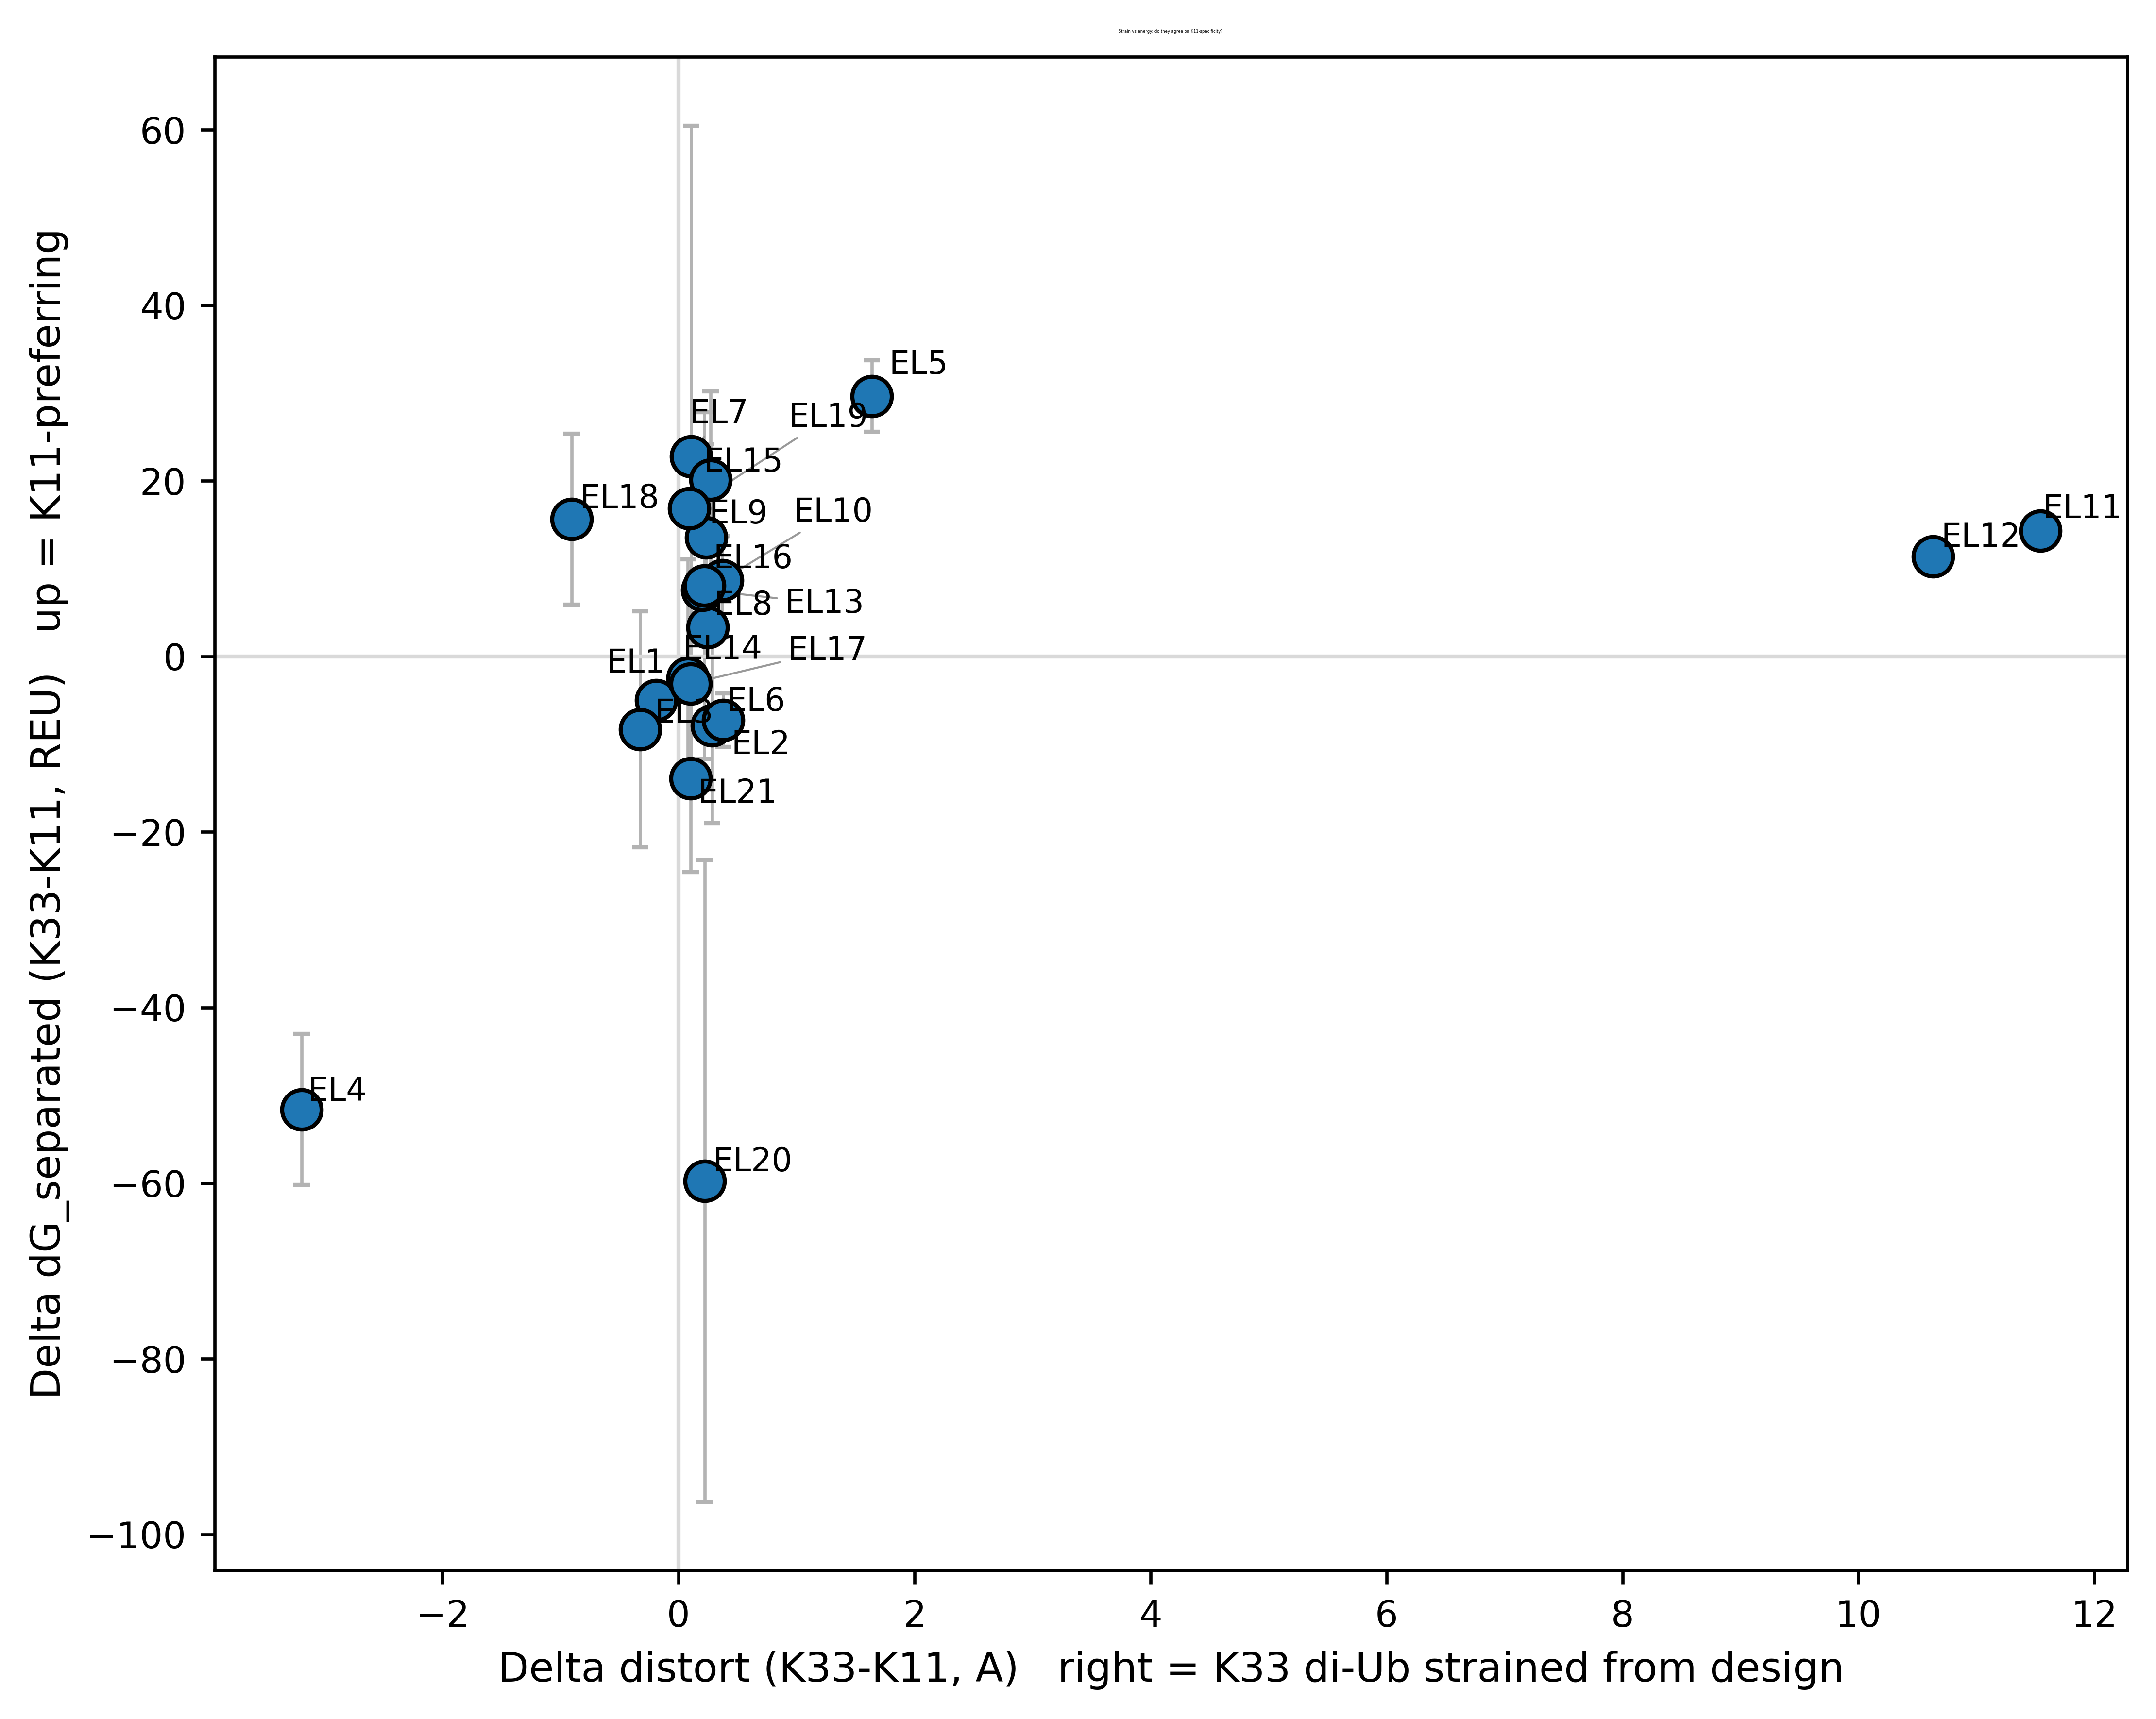

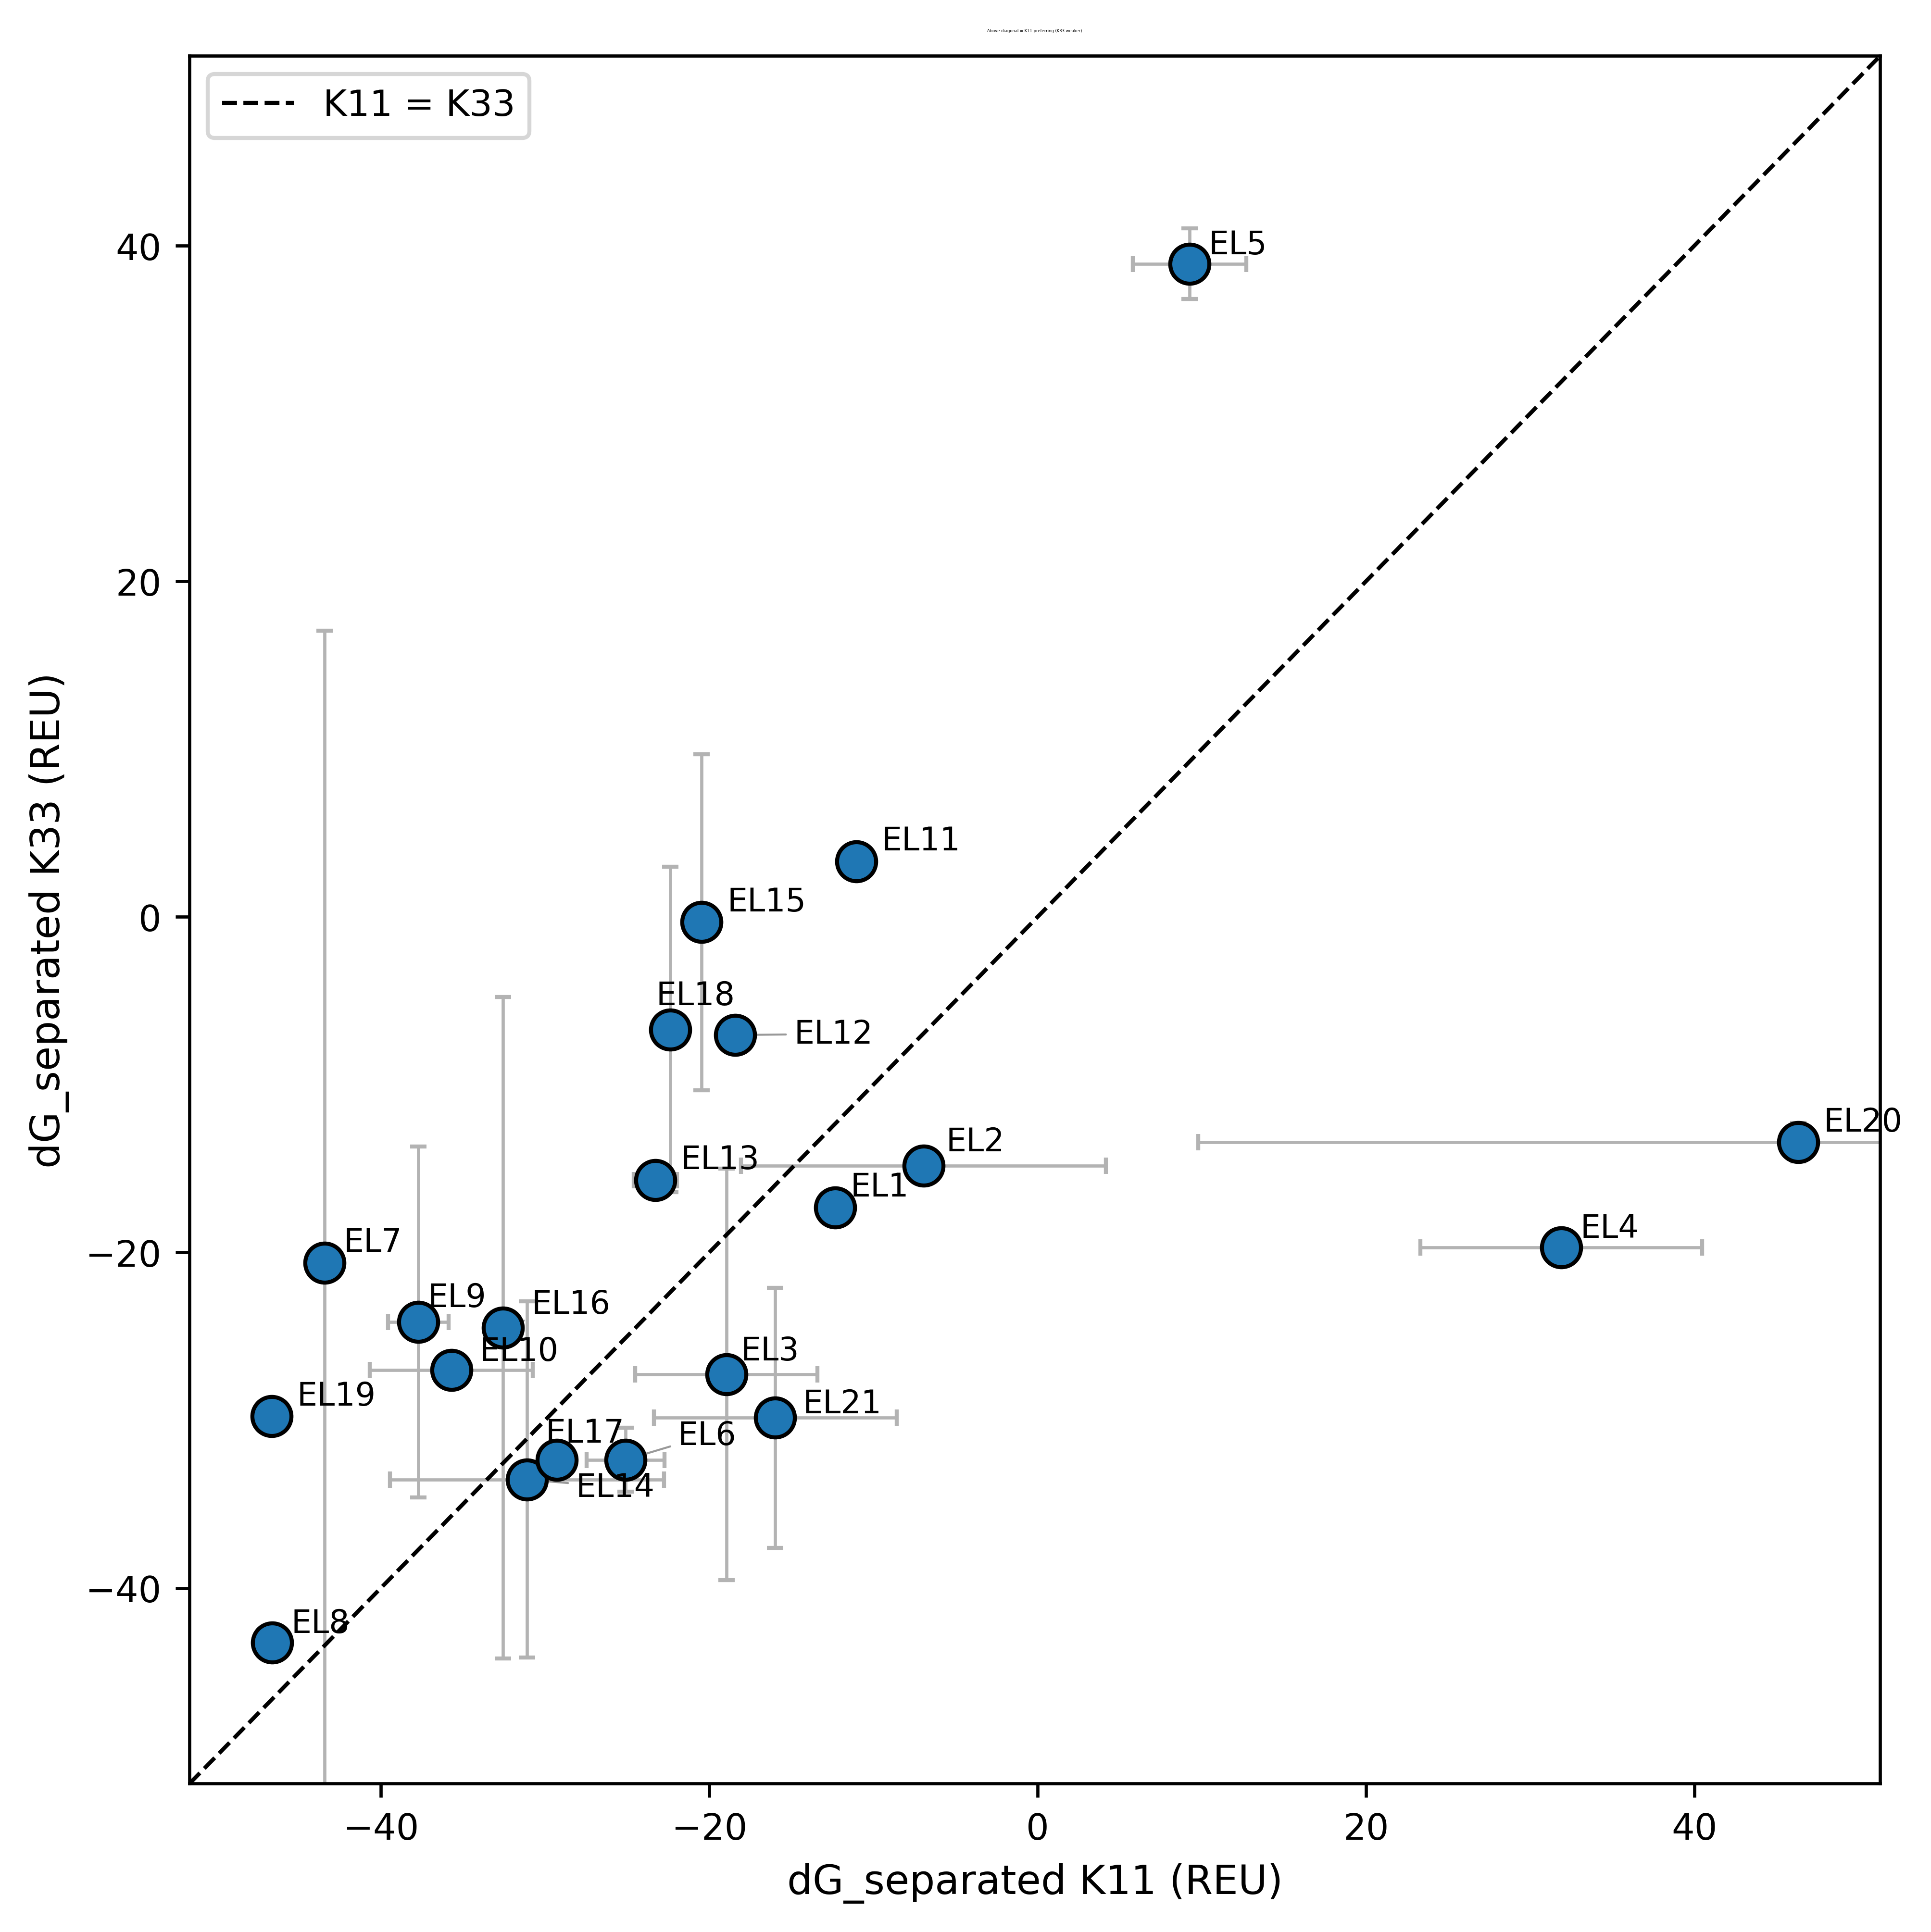

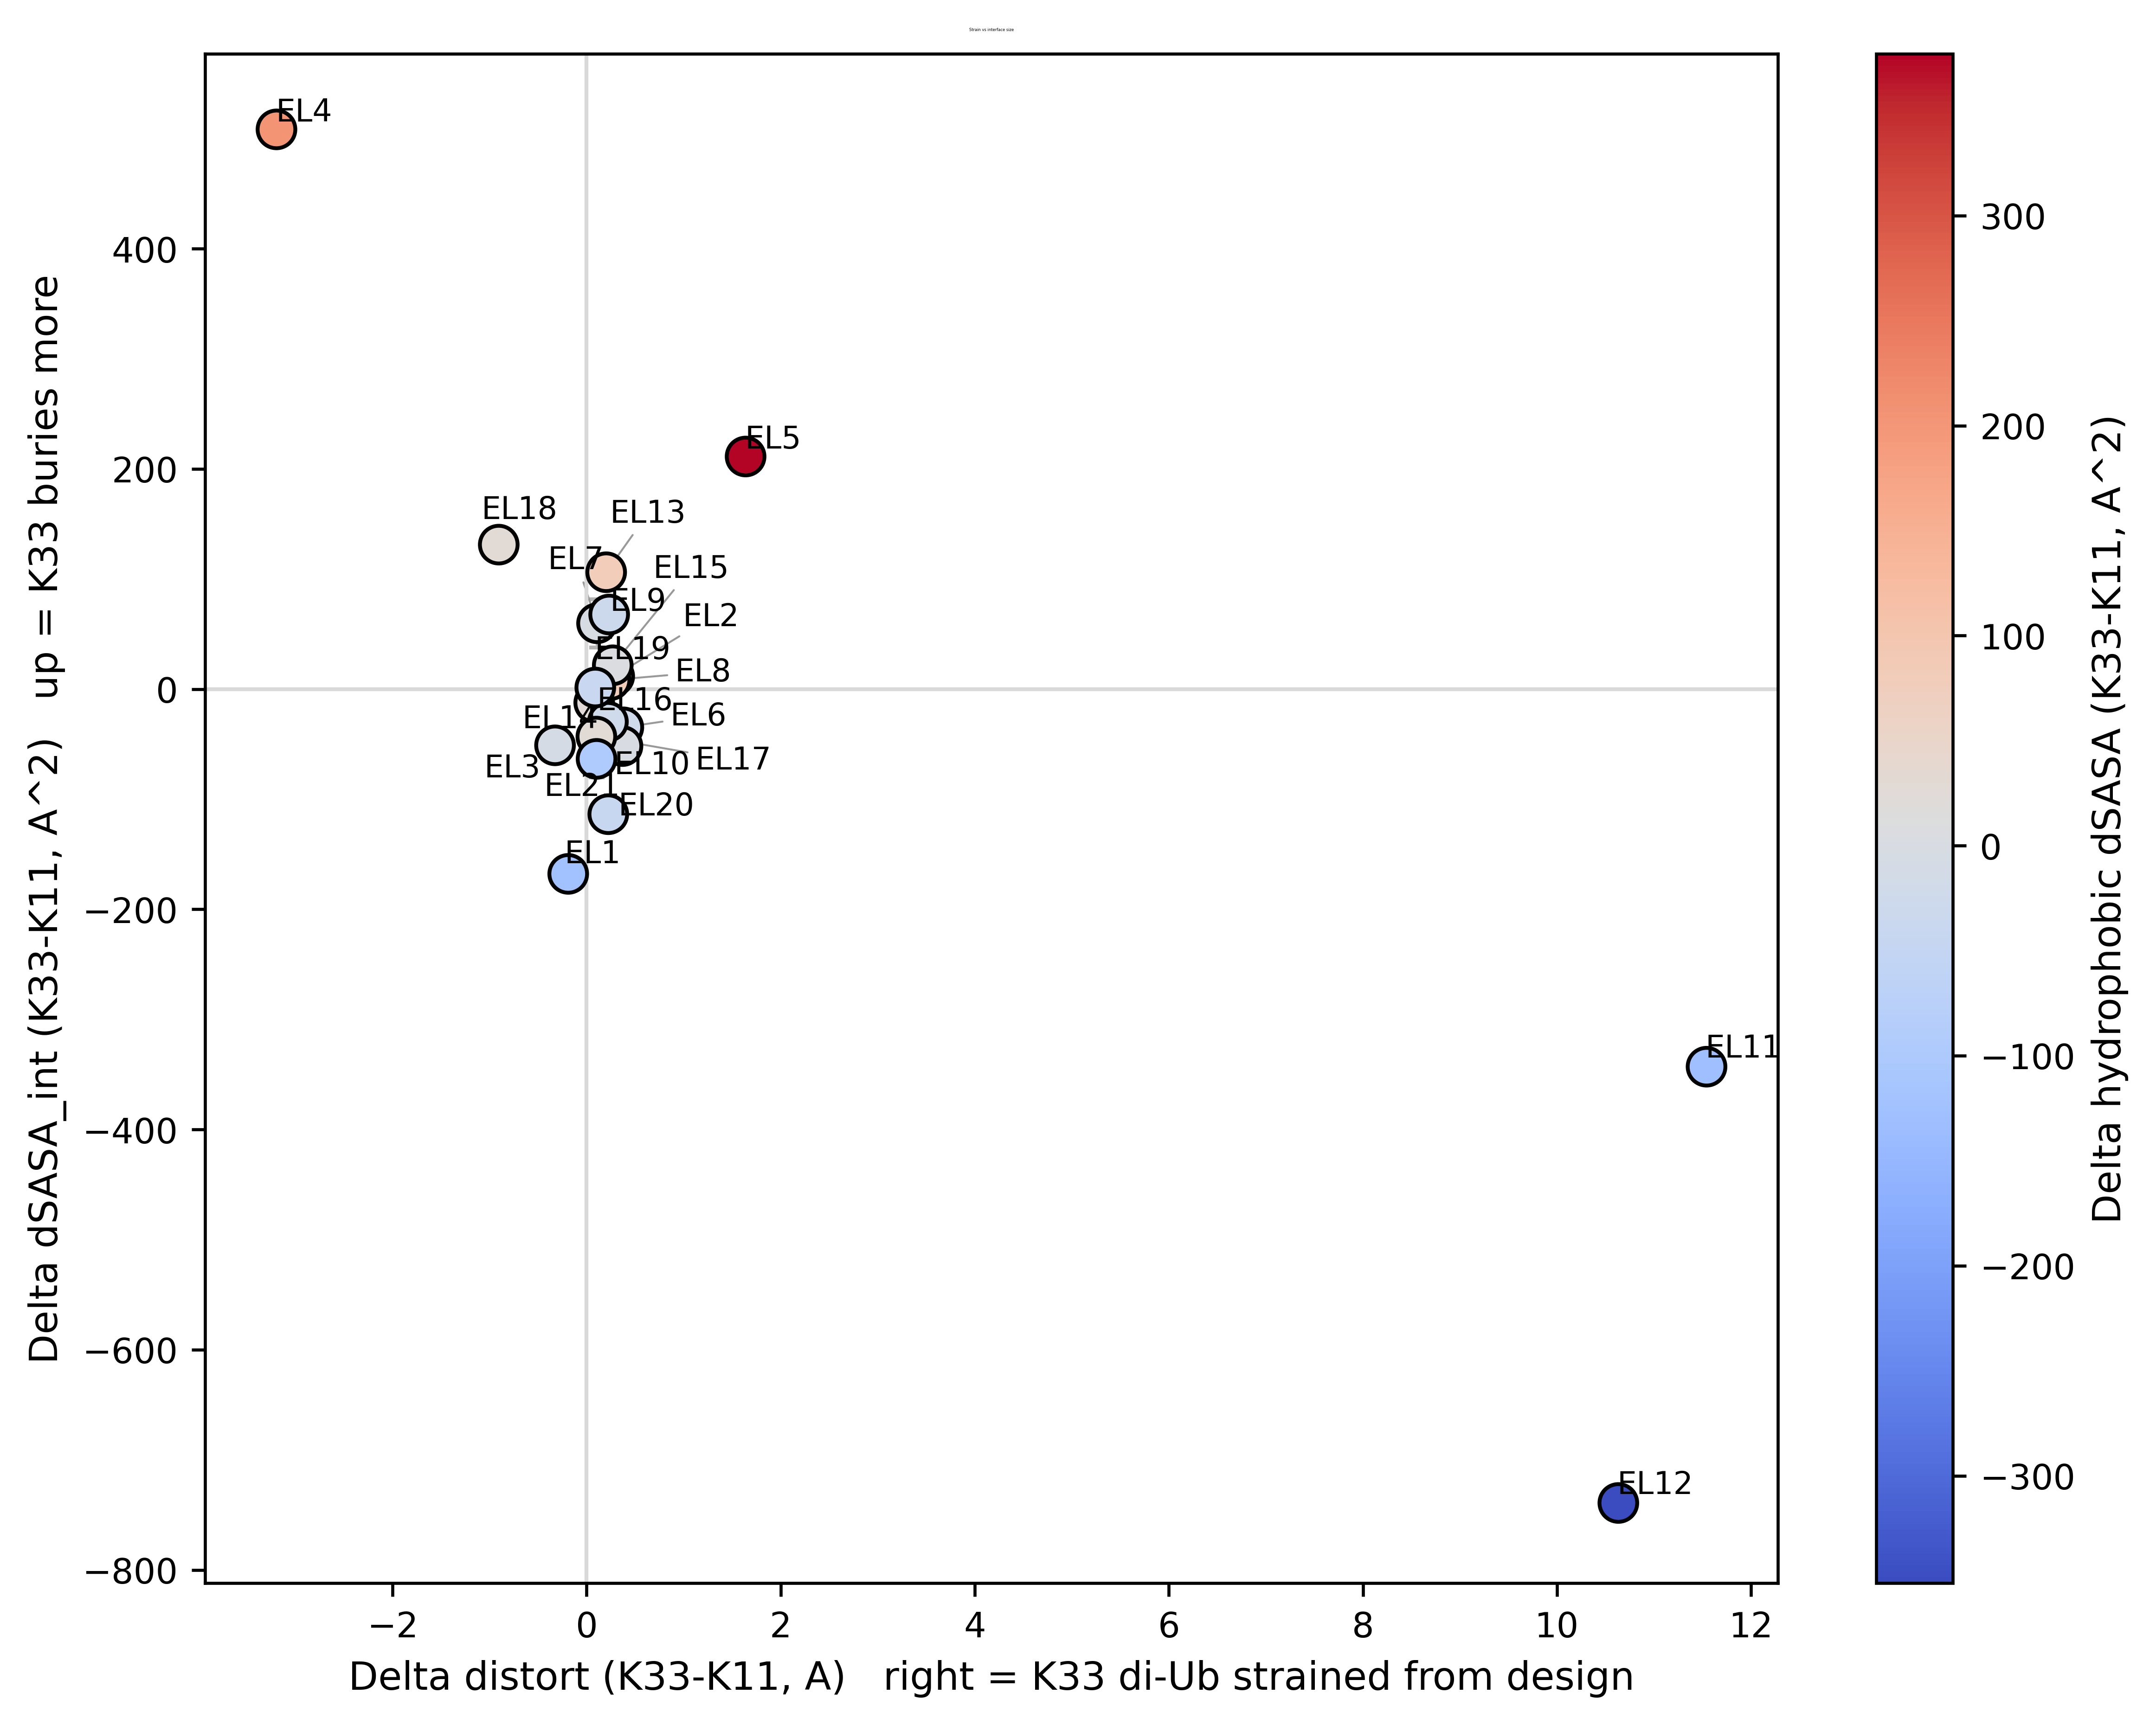

In [ ]:
df = None
if XLSX:
    df = run_all(build_df(XLSX))
else:
    try:
        from google.colab import files
        up = files.upload()
        name = next(iter(up))
        print("loaded:", name)
        df = run_all(build_df(up[name]))
    except ImportError:
        import ipywidgets as widgets
        out = widgets.Output()
        def _on_upload(change):
            val = change["new"]
            if not val: return
            item = next(iter(val.values())) if isinstance(val, dict) else val[0]
            nm = (item.get("metadata", {}) or {}).get("name") or item.get("name", "uploaded.xlsx")
            global df
            with out:
                out.clear_output(wait=True); print("loaded:", nm)
                df = run_all(build_df(bytes(item["content"])))
        u = widgets.FileUpload(accept=".xlsx", multiple=False)
        u.observe(_on_upload, names="value")
        display(widgets.VBox([widgets.HTML("<b>Upload merged triage xlsx:</b>"), u, out]))